<a href="https://colab.research.google.com/github/anastasiafantasia/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E4 — Esercitazione: pulire un dataset nuovo

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrealorenzon/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb)

## Come funziona un'esercitazione

Rispetto alle lezioni, qui hai **meno indicazioni**: per ogni passo trovi l'obiettivo e un **controllo** per verificare di esserci arrivato. Cosa cercare, sta a te (Google, Gemini, le dispense, i notebook delle lezioni).

- 👥 Si lavora in **gruppi da 3**, con tre ruoli che **ruotano a ogni incontro**: chi **scrive** (condivide lo schermo e scrive il codice nel suo notebook), chi **cerca** (Google, Gemini, dispense), chi **controlla** (il risultato ha senso? il numero torna?). Il codice sta tutto nel notebook di chi scrive: a fine lezione lo condivide con gli altri due (**Condividi** → chiunque abbia il link).
- Se il controllo non torna, **non andare avanti**: un errore all'inizio si porta dietro tutto il resto.
- 🆘 Bloccato **fuori dalla lezione**? In Colab: **Condividi** → aggiungi `andrelorenzon+sima2026@gmail.com` come **Editor**, poi scrivigli quale passo non torna.
- **File → Salva una copia in Drive** per non perdere il lavoro.

## Contesto

Un'azienda alimentare ti manda le sue esportazioni mensili del 2022 e del 2023, per paese e prodotto: `esportazioni.xlsx`. Vogliono sapere quanto hanno esportato in ogni paese. Prima, però, i dati vanno puliti: è il lavoro della L3, su un file che non hai mai visto.

Leggi la descrizione delle colonne in [`dati/README.md`](https://github.com/andrealorenzon/SIMA2026/blob/main/dati/README.md): ti servirà.

⏱️ **Prima di iniziare:** se non hai finito il task della L3, completalo ora (circa 20 minuti). Questa esercitazione usa le stesse tecniche su un file nuovo.

A questo notebook hanno lavorato: Anastasia Fantasia, Valeria Faralla, Ylenia Moscheni

## Preparazione

Esegui questa cella così com'è: carica le librerie e il file delle esportazioni nella tabella `ex`.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")

## Parte 1 — Pulizia

### 1. Conosci il file

Guarda le prime righe, le dimensioni e i tipi delle colonne. Scrivi qui sotto **tutti** i problemi che vedi, prima di correggere qualunque cosa.

In [ ]:
# scrivi qui il tuo codice


In [ ]:
# 1. Visualizza le prime righe del dataset
display(ex.head(10))

# 2. Visualizza le dimensioni del dataset (righe, colonne)
print(f"Dimensioni del dataset: {ex.shape}\n")

# 3. Visualizza i tipi di dati delle colonne e i valori non-nulli
print("Informazioni sul dataset:")
ex.info()

,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,"€ 9.912,62"
1,feb 2023,Spagna,Olio EVO 1L,225,"€ 2.069,75"
2,dic 2022,Francia,Parmigiano 1kg,2357,"€ 49.332,02"
3,set 2023,DE,Pasta 500g,357,"€ 644,87"
4,nov 2022,Svizzera,Parmigiano 1kg,373,"€ 7.884,74"
5,ago 2022,Svizzera,Parmigiano 1kg,755,"€ 15.419,72"
6,mar 2022,germania,Olio EVO 1L,406,"€ 3.819,20"
7,mag 2023,Spagna,Olio EVO 1L,495,"€ 4.607,19"
8,feb 2022,FRANCIA,Pasta 500g,-41,"€ -70,94"
9,lug 2022,USA,Passata 700g,180,"€ 428,19"


Dimensioni del dataset: (425, 5)

Informazioni sul dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   mese      425 non-null    object
 1   paese     425 non-null    object
 2   prodotto  425 non-null    object
 3   quantita  425 non-null    int64 
 4   valore    425 non-null    object
dtypes: int64(1), object(4)
memory usage: 16.7+ KB


*Risposta:*
- valori della quantità in negativo; differenze e duplicati nei paesi; la colonna valore è object invece dovrebbe essere un numero; la colonna mese è object ma dovrebbe essere una data.

### 2. Duplicati

Togli le righe duplicate.

✅ *Controllo:* 413 righe.

In [ ]:
# scrivi qui il tuo codice


In [ ]:
# Identifichiamo le righe duplicate (keep=False mostra sia la prima che le successive copie)
duplicati = ex_originale[ex_originale.duplicated(keep=False)]

# Ordiniamo per vedere i duplicati vicini
display(duplicati.sort_values(by=["mese", "paese", "prodotto"]))

,mese,paese,prodotto,quantita,valore
29,dic 2022,Germania,Olio EVO 1L,605,"€ 5.643,79"
346,dic 2022,Germania,Olio EVO 1L,605,"€ 5.643,79"
226,dic 2022,U.S.A.,Parmigiano 1kg,952,"€ 20.013,45"
305,dic 2022,U.S.A.,Parmigiano 1kg,952,"€ 20.013,45"
20,dic 2023,U.S.A.,Olio EVO 1L,355,"€ 3.408,96"
194,dic 2023,U.S.A.,Olio EVO 1L,355,"€ 3.408,96"
97,feb 2022,Svizzera,Pasta 500g,342,"€ 597,59"
308,feb 2022,Svizzera,Pasta 500g,342,"€ 597,59"
99,feb 2023,DE,Parmigiano 1kg,418,"€ 8.702,63"
324,feb 2023,DE,Parmigiano 1kg,418,"€ 8.702,63"


In [ ]:
print(f"Righe prima della rimozione: {len(ex)}")

# Rimuove le righe duplicate mantenendo solo la prima occorrenza
ex = ex.drop_duplicates()

print(f"Righe dopo la rimozione (controllo): {len(ex)}")

Righe prima della rimozione: 425
Righe dopo la rimozione (controllo): 413


### 3. Paesi

Fai in modo che ogni paese sia scritto in un solo modo, in italiano.

✅ *Controllo:* `ex["paese"].nunique()` dà 5.

In [ ]:
# 1. Vediamo i nomi unici attuali dei paesi
print("Paesi unici prima della pulizia:")
print(ex["paese"].unique())
print(f"Numero di paesi unici: {ex['paese'].nunique()}\n")

Paesi unici prima della pulizia:
['Germany' 'Spagna ' 'Francia' 'DE' 'Svizzera' 'germania' 'FRANCIA' 'USA'
 'U.S.A.' 'Spagna' 'Germania' 'France' 'Stati Uniti']
Numero di paesi unici: 13



In [ ]:
# 2. Definiamo un dizionario per mappare le varianti al nome standard in italiano
mappa_paesi = {
    'Germany': 'Germania',
    'DE': 'Germania',
    'germania': 'Germania',
    'France': 'Francia',
    'FRANCIA': 'Francia',
    'USA': 'Stati Uniti',
    'U.S.A.': 'Stati Uniti',
    'Spain': 'Spagna',
    'Svizzera': 'Svizzera'
}

# Applichiamo la sostituzione e rimuoviamo eventuali spazi bianchi extra
ex['paese'] = ex['paese'].str.strip().replace(mappa_paesi)

# 3. Verifichiamo il risultato
print("Paesi unici dopo la pulizia:")
print(ex["paese"].unique())
print(f"Numero di paesi unici (controllo): {ex['paese'].nunique()}")

Paesi unici dopo la pulizia:
['Germania' 'Spagna' 'Francia' 'Svizzera' 'Stati Uniti']
Numero di paesi unici (controllo): 5


In [ ]:
# scrivi qui il tuo codice


### 4. Valore

Trasforma `valore` in numero (euro). Prima conta quante celle contengono solo un trattino `"-"`: dopo la conversione devono essere gli unici valori mancanti.

✅ *Controllo:* tanti valori mancanti quanti erano i trattini (9), e il primo valore della tabella è un numero con i decimali giusti.

In [ ]:
# Conta e mostra le righe in cui la colonna 'valore' è esattamente un trattino
righe_con_trattino = ex[ex['valore'].str.strip() == '-']

print(f"Numero di righe con solo un trattino: {len(righe_con_trattino)}")
display(righe_con_trattino)

Numero di righe con solo un trattino: 9


,mese,paese,prodotto,quantita,valore
46,feb 2022,Stati Uniti,Olio EVO 1L,214,-
50,ott 2023,Stati Uniti,Passata 700g,315,-
54,gen 2023,Svizzera,Olio EVO 1L,367,-
120,lug 2023,Germania,Pasta 500g,727,-
187,nov 2022,Spagna,Pasta 500g,517,-
189,lug 2023,Germania,Olio EVO 1L,108,-
270,mar 2022,Francia,Pasta 500g,397,-
284,set 2023,Germania,Parmigiano 1kg,378,-
357,ago 2022,Stati Uniti,Parmigiano 1kg,483,-


In [ ]:
# scrivi qui il tuo codice


In [ ]:
# 1. Puliamo il testo nella colonna valore
ex['valore'] = ex['valore'].str.replace('€', '', regex=False)
ex['valore'] = ex['valore'].str.replace('.', '', regex=False)
ex['valore'] = ex['valore'].str.replace(',', '.', regex=False)

# 2. Convertiamo in numero reale (i trattini '-' diventeranno automaticamente NaN)
ex['valore'] = pd.to_numeric(ex['valore'], errors='coerce')

# 3. Verifichiamo il controllo: quanti valori mancanti ci sono? (Devono essere 9)
nulli_valore = ex['valore'].isna().sum()
print(f"Numero di valori mancanti (NaN) in valore: {nulli_valore} (Controllo: 9)")

# 4. Mostriamo le prime righe per verificare che i decimali siano corretti
display(ex.head())

Numero di valori mancanti (NaN) in valore: 9 (Controllo: 9)


,mese,paese,prodotto,quantita,valore
0,set 2022,Germania,Parmigiano 1kg,471,9912.62
1,feb 2023,Spagna,Olio EVO 1L,225,2069.75
2,dic 2022,Francia,Parmigiano 1kg,2357,49332.02
3,set 2023,Germania,Pasta 500g,357,644.87
4,nov 2022,Svizzera,Parmigiano 1kg,373,7884.74


In [ ]:
# Filtra e mostra le righe che hanno un valore nullo (NaN) nella colonna 'valore'
righe_nan = ex[ex['valore'].isna()]
display(righe_nan)

,mese,paese,prodotto,quantita,valore
46,feb 2022,Stati Uniti,Olio EVO 1L,214,NaN
50,ott 2023,Stati Uniti,Passata 700g,315,NaN
54,gen 2023,Svizzera,Olio EVO 1L,367,NaN
120,lug 2023,Germania,Pasta 500g,727,NaN
187,nov 2022,Spagna,Pasta 500g,517,NaN
189,lug 2023,Germania,Olio EVO 1L,108,NaN
270,mar 2022,Francia,Pasta 500g,397,NaN
284,set 2023,Germania,Parmigiano 1kg,378,NaN
357,ago 2022,Stati Uniti,Parmigiano 1kg,483,NaN


### 5. Mese

Trasforma `mese` (per esempio `"set 2022"`) in una vera data, il primo giorno del mese. Python non conosce le abbreviazioni dei mesi in italiano: il dizionario qui sotto può aiutarti.

✅ *Controllo:* 24 mesi diversi, nessuna data mancante, dal gennaio 2022 al dicembre 2023.

🔎 *Da cercare:* `pandas str split expand` · `pandas map dizionario` · `pandas to_datetime`

In [ ]:
mesi = {"gen": 1, "feb": 2, "mar": 3, "apr": 4, "mag": 5, "giu": 6,
        "lug": 7, "ago": 8, "set": 9, "ott": 10, "nov": 11, "dic": 12}

# 1. Dividiamo la colonna 'mese' in due colonne separate: nome del mese e anno
df_mesi = ex['mese'].str.split(expand=True)
df_mesi.columns = ['nome_mese', 'anno']

# 2. Mappiamo il nome del mese in italiano al rispettivo numero
df_mesi['num_mese'] = df_mesi['nome_mese'].map(mesi)

# 3. Creiamo una stringa provvisoria nel formato standard "YYYY-MM-01"
date_stringhe = df_mesi['anno'] + '-' + df_mesi['num_mese'].astype(str) + '-01'

# 4. Convertiamo le stringhe in vere date e aggiorniamo il DataFrame originale
ex['mese'] = pd.to_datetime(date_stringhe, format='%Y-%m-%d')

# --- CONTROLLI ---
print(f"Numero di date uniche (Controllo: 24): {ex['mese'].nunique()}")
print(f"Numero di date mancanti (Controllo: 0): {ex['mese'].isna().sum()}")
print(f"Data minima: {ex['mese'].min()}")
print(f"Data massima: {ex['mese'].max()}")
print("\nAnteprima delle prime righe con le nuove date:")
display(ex.head())

Numero di date uniche (Controllo: 24): 24
Numero di date mancanti (Controllo: 0): 0
Data minima: 2022-01-01 00:00:00
Data massima: 2023-12-01 00:00:00

Anteprima delle prime righe con le nuove date:


,mese,paese,prodotto,quantita,valore
0,2022-09-01,Germania,Parmigiano 1kg,471,9912.62
1,2023-02-01,Spagna,Olio EVO 1L,225,2069.75
2,2022-12-01,Francia,Parmigiano 1kg,2357,49332.02
3,2023-09-01,Germania,Pasta 500g,357,644.87
4,2022-11-01,Svizzera,Parmigiano 1kg,373,7884.74


### 6. Quantità negative

Quante righe hanno una quantità negativa? Sono errori da correggere? Leggi la descrizione delle colonne prima di decidere, e scrivi la tua decisione.

In [ ]:
# Filtra e mostra le righe con quantità negativa
negative_qty = ex[ex['quantita'] < 0]

print(f"Numero di righe con quantità negativa: {len(negative_qty)}")
display(negative_qty)

Numero di righe con quantità negativa: 11


,mese,paese,prodotto,quantita,valore
8,2022-02-01,Francia,Pasta 500g,-41,-70.94
28,2023-08-01,Stati Uniti,Passata 700g,-27,-63.07
125,2023-06-01,Francia,Olio EVO 1L,-59,-517.02
183,2022-12-01,Stati Uniti,Pasta 500g,-87,-163.87
186,2023-04-01,Svizzera,Olio EVO 1L,-74,-699.01
237,2023-11-01,Francia,Pasta 500g,-39,-65.19
273,2022-07-01,Svizzera,Pasta 500g,-20,-36.15
320,2022-09-01,Francia,Parmigiano 1kg,-134,-2832.48
385,2022-07-01,Svizzera,Olio EVO 1L,-23,-214.88
401,2023-04-01,Spagna,Pasta 500g,-39,-70.03


*Risposta:* quantità sarebbe da correggere; il valore dovrebbe essere corretto se non dipende direttamente dalla quantità

## Parte 2 — Le domande dell'azienda

### 7. Per paese

Quanto ha esportato l'azienda in ogni paese nel 2023, in euro? Ordina dal paese più importante.

Per tenere solo il 2023: `data` ora è una vera data, e da una data si può estrarre l'anno (cerca `pandas dt year`).

✅ *Controllo:* 5 righe.

In [ ]:
# 1. Filtriamo il dataset per tenere solo le esportazioni del 2023
esportazioni_2023 = ex[ex['mese'].dt.year == 2023]

# 2. Raggruppiamo per paese, sommiamo la colonna 'valore' e ordiniamo in modo decrescente
export_per_paese_2023 = (esportazioni_2023
                         .groupby('paese')['valore']
                         .sum()
                         .sort_values(ascending=False)
                         .reset_index())

# Rinominiamo la colonna per chiarezza
export_per_paese_2023.columns = ['Paese', 'Totale Esportato (€)']

# Visualizziamo il risultato (Controllo: 5 righe)
display(export_per_paese_2023)

,Paese,Totale Esportato (€)
0,Svizzera,237899.48
1,Francia,232701.46
2,Spagna,191485.78
3,Stati Uniti,159594.97
4,Germania,146573.67


### 8. Nel tempo

Disegna l'andamento del valore esportato totale, mese per mese. C'è un periodo dell'anno in cui si esporta di più?

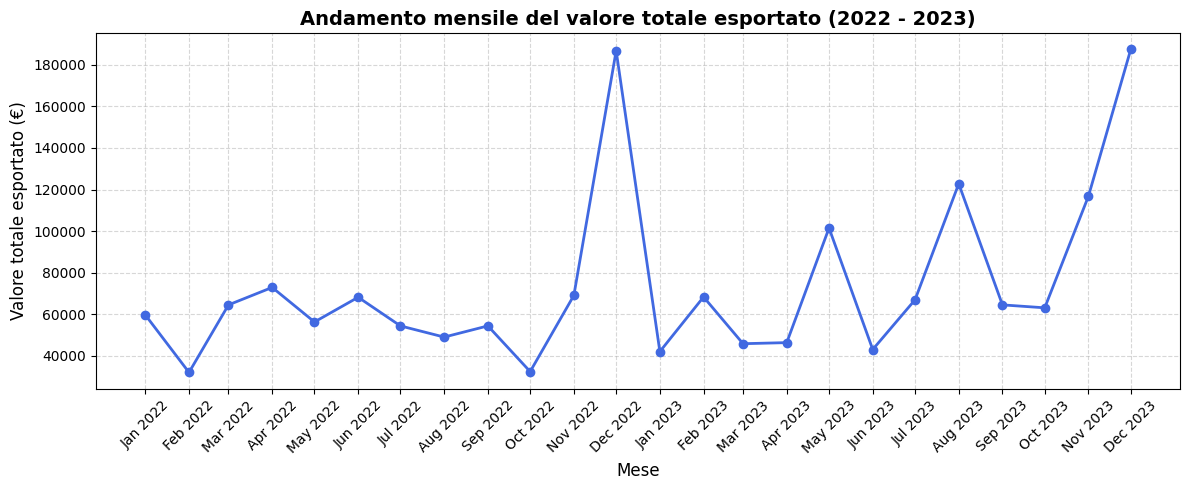

In [ ]:
# 1. Raggruppiamo per mese e sommiamo il valore totale esportato
andamento_temporale = ex.groupby('mese')['valore'].sum().reset_index()

# 2. Creiamo il grafico
plt.figure(figsize=(12, 5))
plt.plot(andamento_temporale['mese'], andamento_temporale['valore'], marker='o', color='royalblue', linewidth=2)

# Personalizzazioni grafiche
plt.title("Andamento mensile del valore totale esportato (2022 - 2023)", fontsize=14, fontweight='bold')
plt.xlabel("Mese", fontsize=12)
plt.ylabel("Valore totale esportato (€)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(andamento_temporale['mese'], andamento_temporale['mese'].dt.strftime('%b %Y'), rotation=45)
plt.tight_layout()

# 3. Mostriamo il grafico
plt.show()

*Risposta:* dicembre

### 9. Un controllo di plausibilità

Calcola il prezzo medio implicito di ogni prodotto (valore totale diviso quantità totale). I prezzi hanno senso per quei prodotti?

In [ ]:
# Raggruppiamo per prodotto calcolando la somma di valore e quantità
prezzi_medi = ex.groupby('prodotto').agg(
    valore_totale=('valore', 'sum'),
    quantita_totale=('quantita', 'sum')
).reset_index()

# Calcoliamo il prezzo medio implicito (valore totale / quantità totale)
prezzi_medi['prezzo_medio_implicito'] = prezzi_medi['valore_totale'] / prezzi_medi['quantita_totale']

# Mostriamo la tabella risultante
display(prezzi_medi)

,prodotto,valore_totale,quantita_totale,prezzo_medio_implicito
0,Olio EVO 1L,440041.83,46782,9.406221
1,Parmigiano 1kg,1108889.97,53709,20.646260
2,Passata 700g,128780.69,54110,2.379979
3,Pasta 500g,89754.59,51387,1.746640


*Risposta:* si

## Le tue decisioni

Scrivi la tabella delle decisioni di pulizia che hai preso (problema, decisione, verifica), come nel debrief della L3.

*Risposta:*
| Problema | Decisione | Verifica |
|righe duplicate|rimosse|abbiamo mostrato le correzioni
| presenza di trattini per alcuni valori e valori che non erano numeri | abbiamo modificato i trattini in dato mancante e i valori in numeri | abbiamo verificato le correzioni |
| paesi scritti in maniera diversa | abbiamo uniformato e mantenuto una sola versione per paese | abbiamo verificato le correzioni |
| date risultavano mese + anno | abbiamo inserito come giorno il primo del mese e trasformato in data | abbiamo verificato le correzioni |